# 01 – Grid

**Goal:** load the SURS 100 m grid for Ljubljana (MOL), check that it is correct, look at population, and save a clean grid that every later notebook builds on.

- **Input:** `data/raw/LJ_prebivalstvo_MOL_100m_2025/` (SURS population, 1 Jan 2025, already clipped to MOL)
- **Output:** `data/processed/cells.gpkg` (one row per 100 m cell, with a stable `cell_id`)

Why a grid? Every data layer (imperviousness, NDVI, POIs, ...) comes in a different shape: rasters, points, polygons.
To compare them, we summarise each layer **per grid cell**. The grid is the common table, and each layer adds columns to it.

## 1. Setup
Imports and paths. Paths are relative to the project folder, so the notebook works on any computer.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

# The notebook runs from notebooks/, the project root is one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "LJ_prebivalstvo_MOL_100m_2025"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

CRS = "EPSG:3794"  # D96/TM, Slovenian national grid in metres
CELL_SIZE = 100    # metres

print(ROOT)

C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis


## 2. Load the data
Two files:
- `celice_100m`: one polygon per 100 × 100 m cell, with 49 SURS variables
- `obcina_ljubljana`: the MOL boundary (from OpenStreetMap), used only for checks and maps

In [2]:
grid = gpd.read_file(RAW / "prebivalstvo_100m_2025-01-01_ljubljana.gpkg", layer="celice_100m")
mol = gpd.read_file(RAW / "obcina_ljubljana.gpkg")

print(f"{len(grid):,} cells, {grid.shape[1]} columns, CRS = {grid.crs}")
grid[["ime_celice", "E", "N", "tot_p", "p_00_14", "p_65_", "surs_celica", "kolektivno"]].head()

27,505 cells, 57 columns, CRS = EPSG:3794


,ime_celice,E,N,tot_p,p_00_14,p_65_,surs_celica,kolektivno
0,SIHM100_4618_1118,461800,111800,0.0,0.0,0.0,0.0,0
1,SIHM100_4619_1118,461900,111800,0.0,0.0,0.0,0.0,0
2,SIHM100_4618_1117,461800,111700,0.0,0.0,0.0,0.0,0
3,SIHM100_4619_1117,461900,111700,0.0,0.0,0.0,0.0,0
4,SIHM100_4620_1117,462000,111700,0.0,0.0,0.0,0.0,0


## 3. Sanity checks
Before using any dataset, check that it is what we think it is. Each `assert` stops the notebook with an error if something is wrong.

1. coordinate system is EPSG:3794
2. every cell has a unique ID
3. every cell is exactly 100 × 100 m
4. the ID matches the coordinates (`SIHM100_X_Y` where X = E/100, Y = N/100, lower-left corner)
5. every cell lies inside MOL

In [3]:
assert grid.crs.to_epsg() == 3794 and mol.crs.to_epsg() == 3794
assert grid["ime_celice"].is_unique

bounds = grid.bounds
assert np.allclose(bounds.maxx - bounds.minx, CELL_SIZE) and np.allclose(bounds.maxy - bounds.miny, CELL_SIZE)

expected_id = "SIHM100_" + (grid["E"] // 100).astype(int).astype(str) + "_" + (grid["N"] // 100).astype(int).astype(str)
assert (expected_id == grid["ime_celice"]).all()
assert np.allclose(bounds.minx, grid["E"]) and np.allclose(bounds.miny, grid["N"])

assert grid.centroid.within(mol.union_all()).all()

print("All checks passed.")
print(f"MOL area: {mol.area.sum() / 1e6:.1f} km²  vs  grid: {len(grid) * CELL_SIZE**2 / 1e6:.1f} km²")

All checks passed.
MOL area: 275.0 km²  vs  grid: 275.1 km²


## 4. Who lives where?
Important details from `PREBERI.txt`:
- `surs_celica = 1` means SURS has registered residents in the cell. **Use this to decide if a cell is populated**, not `tot_p > 0`.
- SURS adds small random noise to counts for privacy, so a populated cell can show `tot_p = 0`.
- One cell (`kolektivno = 1`) contains student dorms: almost 3,000 people, mostly 20–24 years old. It is a real place, but an extreme outlier.

In [4]:
populated = grid["surs_celica"] == 1
print(f"Populated cells:      {populated.sum():,} of {len(grid):,} ({populated.mean():.0%})")
print(f"Total population:     {grid['tot_p'].sum():,.0f}")
print(f"Populated but tot_p=0 (noise): {(populated & (grid['tot_p'] == 0)).sum()}")
print()
print("Residents per populated cell:")
print(grid.loc[populated, "tot_p"].describe().round(1))
print()
grid.loc[grid["kolektivno"] == 1, ["ime_celice", "tot_p", "p_20_24"]]

Populated cells:      5,844 of 27,505 (21%)
Total population:     300,443
Populated but tot_p=0 (noise): 81

Residents per populated cell:
count    5844.0
mean       51.4
std        81.9
min         0.0
25%         8.0
50%        26.0
75%        60.0
max      2843.0
Name: tot_p, dtype: float64



,ime_celice,tot_p,p_20_24
13661,SIHM100_4603_1014,2843.0,2187.0


Each cell is exactly 1 hectare, so **`tot_p` is already population density in people per hectare**.

The distribution is very skewed: most cells have a few dozen people, a few have hundreds.
That is why the histogram and the map below use a **log scale**. Without it, a handful of dense cells would dominate and everything else would look the same.

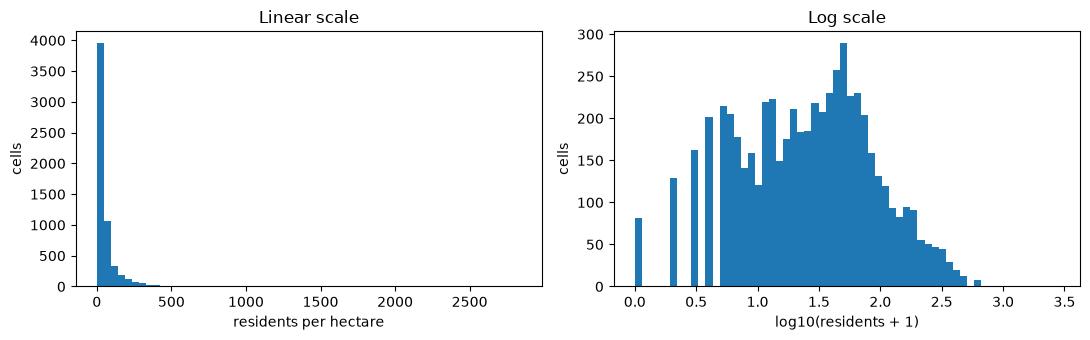

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
values = grid.loc[populated, "tot_p"]

axes[0].hist(values, bins=60)
axes[0].set(title="Linear scale", xlabel="residents per hectare", ylabel="cells")

axes[1].hist(np.log10(values + 1), bins=60)
axes[1].set(title="Log scale", xlabel="log10(residents + 1)", ylabel="cells")

plt.tight_layout()
plt.show()

## 5. Map of population density
Grey = no registered residents (forest, fields, industry, parks, roads). Coloured = populated cells.

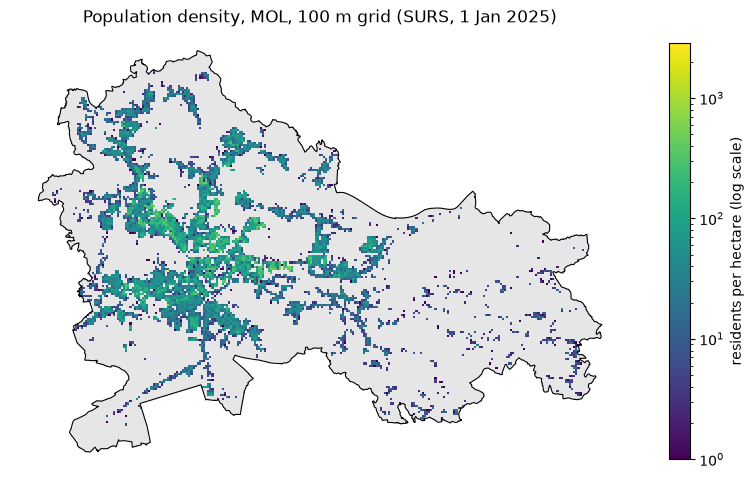

In [6]:
fig, ax = plt.subplots(figsize=(10, 9))

grid[~populated].plot(ax=ax, color="#e6e6e6", linewidth=0)
# clip(lower=1): populated cells with noise-induced tot_p = 0 get the lowest colour (log(0) is undefined)
grid[populated].assign(density=grid["tot_p"].clip(lower=1)).plot(
    ax=ax, column="density", cmap="viridis", linewidth=0,
    norm=LogNorm(vmin=1, vmax=grid["tot_p"].max()),
    legend=True, legend_kwds={"label": "residents per hectare (log scale)", "shrink": 0.6},
)
mol.boundary.plot(ax=ax, color="black", linewidth=0.8)

ax.set_title("Population density, MOL, 100 m grid (SURS, 1 Jan 2025)")
ax.set_axis_off()

FIGURES.mkdir(exist_ok=True)
fig.savefig(FIGURES / "01_population_density.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save a clean grid
We keep only what later notebooks need, with clear English names:

| column | meaning | role |
|---|---|---|
| `cell_id` | SURS cell ID, the key for joining all layers | ID |
| `E`, `N` | lower-left corner in metres (EPSG:3794) | ID |
| `populated` | SURS has registered residents | flag |
| `collective` | collective housing (student dorms) | flag, outlier handling |
| `pop` | residents per hectare | **input** (people) |
| `pop_0_14`, `pop_65plus` | residents aged 0–14 and 65+ | **interpretation only, never an input** |

The full 49-variable table always stays available in `data/raw/`.

In [7]:
cells = gpd.GeoDataFrame(
    {
        "cell_id": grid["ime_celice"],
        "E": grid["E"].astype(int),
        "N": grid["N"].astype(int),
        "populated": populated,
        "collective": grid["kolektivno"] == 1,
        "pop": grid["tot_p"],
        "pop_0_14": grid["p_00_14"],
        "pop_65plus": grid["p_65_"],
    },
    geometry=grid.geometry,
    crs=CRS,
).sort_values(["N", "E"]).reset_index(drop=True)

PROCESSED.mkdir(exist_ok=True)
cells.to_file(PROCESSED / "cells.gpkg", layer="cells", driver="GPKG")

print(f"Saved {len(cells):,} cells to {PROCESSED / 'cells.gpkg'}")
cells.head()

Saved 27,505 cells to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\cells.gpkg


,cell_id,E,N,populated,collective,pop,pop_0_14,pop_65plus,geometry
0,SIHM100_4564_929,456400,92900,False,False,0.0,0.0,0.0,"POLYGON ((456500 92900, 456500 93000, 456400 9..."
1,SIHM100_4565_929,456500,92900,False,False,0.0,0.0,0.0,"POLYGON ((456600 92900, 456600 93000, 456500 9..."
2,SIHM100_4566_929,456600,92900,False,False,0.0,0.0,0.0,"POLYGON ((456700 92900, 456700 93000, 456600 9..."
3,SIHM100_4567_929,456700,92900,False,False,0.0,0.0,0.0,"POLYGON ((456800 92900, 456800 93000, 456700 9..."
4,SIHM100_4570_929,457000,92900,True,False,7.0,3.0,0.0,"POLYGON ((457100 92900, 457100 93000, 457000 9..."


## Summary and next steps
- The grid is correct: 27,505 cells of 1 ha, EPSG:3794, all inside MOL.
- 5,844 cells (21%) are populated, with about 300,000 residents in total.
- Saved: `data/processed/cells.gpkg` and `figures/01_population_density.png`.

**Open points (decide later, not now):**
- Do we cluster **all** cells, or only populated or built-up ones? Unpopulated cells include forest as well as industry, so `pop = 0` alone does not describe them.
- Water cells will be masked later with NDWI.
- Household size is not in this SURS export. Check whether a separate SURS file is needed.

**Next:** `02_indicators`: add imperviousness and NDVI as mean values per cell.